# GHG Transition-Risk Communication Figures
## Greenings Backtesting Portfolio — MADE / NGFS Alignment

Three simplified figures showing the **worst- and best-case IPCC scenario outcome per project**,
benchmarked against the UBA Methodological Convention 4.0 Central value factor (412.50 USD/tCO₂e, 2030).

| Figure | Message | Design |
|--------|---------|--------|
| **Fig 1 — Per Project** | Range of outcomes across all 6 SSPs per project | Dot-range chart: worst · UBA · best |
| **Fig 2 — Sector** | Which sector carries the most transition risk? | Grouped bars: worst / UBA / best per sector |
| **Fig 3 — Geography** | Country exposure varies dramatically | Range bars: worst-to-best per country with UBA marker |

**Data sources**
- Avoided GHG: `03_monetisation_inputs.csv`
- Supply-chain GHG: Exiobase 3.8.1 via `tvp_io_lib.tier0_impact` / `tier1_impact`
- WifOR 2030 GHG value factors: `2024-11-18_formatted_MonGHG_my.h5`
- UBA 4.0: `01_uba4_ghg.csv` (PRTP 1 %, CO₂_CO₂eq, EUR → USD ×1.10)
- REMIND-MAgPIE R5 multipliers: IPCC AR6 WG3 Ch. 3 / Annex III

In [1]:
import os, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

warnings.filterwarnings('ignore')
%matplotlib inline

# ── Paths ──────────────────────────────────────────────────────────────────────
ROOT    = Path('..').resolve()                              # tvp_backtesting/
FIG_DIR = ROOT / 'project_assessment' / 'greenings_backtesting'
FIG_DIR.mkdir(exist_ok=True)

sys.path.insert(0, str(ROOT / 'tvp_dbio'))
os.environ.setdefault('HDF5_USE_FILE_LOCKING', 'FALSE')

from tvp_io_lib import tier0_impact, tier1_impact

print('Imports OK')

Imports OK


In [2]:
# ── Thermal-gradient SSP colour palette (blue = safe → red = dangerous) ────────
SSP_COLORS = {
    'SSP1-1.9': '#0d47a1',   # deep blue   – < 1.5 °C
    'SSP1-2.6': '#1976d2',   # medium blue – < 2 °C
    'SSP2-4.5': '#26a69a',   # teal        – ~2–2.5 °C  (Paris update)
    'SSP4-6.0': '#ff9800',   # amber       – ~3 °C
    'SSP3-7.0': '#e64a19',   # orange-red  – ~3 °C baseline
    'SSP5-8.5': '#b71c1c',   # deep red    – > 3 °C
}

# ── Project definitions ─────────────────────────────────────────────────────────
PROJECTS = [
    dict(project_id='HOSP-1',  label='HOSP-1\nHospital · LATAM',   sector='Health_Social',      region='LATAM',   capex_musd=147),
    dict(project_id='HOSP-2',  label='HOSP-2\nHospital · Africa',  sector='Health_Specialized', region='Africa',  capex_musd=250),
    dict(project_id='HOSP-3',  label='HOSP-3\nHospital · Europe',  sector='Health_General',     region='Europe',  capex_musd=150),
    dict(project_id='HYDRO-1', label='HYDRO-1\nHydro · Africa',    sector='Energy',             region='Africa',  capex_musd=200),
    dict(project_id='HYDRO-2', label='HYDRO-2\nHydro · Asia',      sector='Energy',             region='Asia',    capex_musd=400),
    dict(project_id='HYDRO-3', label='HYDRO-3\nHydro · Europe',    sector='Energy',             region='Europe',  capex_musd=47),
    dict(project_id='RAIL-1',  label='RAIL-1\nRail Dev · Europe',  sector='Rail_Dev',           region='Europe',  capex_musd=1190),
    dict(project_id='RAIL-2',  label='RAIL-2\nRail Op · Europe',   sector='Rail_Op',            region='Europe',  capex_musd=1350),
    dict(project_id='RAIL-3',  label='RAIL-3\nRail Op · Europe',   sector='Rail_Op',            region='Europe',  capex_musd=2460),
]

PROJ_EXT = {
    'HOSP-1':  dict(iso3='COL', nace='Q',    country='Colombia'),
    'HOSP-2':  dict(iso3='KEN', nace='Q',    country='Kenya'),
    'HOSP-3':  dict(iso3='DEU', nace='Q',    country='Germany'),
    'HYDRO-1': dict(iso3='ETH', nace='D35',  country='Ethiopia'),
    'HYDRO-2': dict(iso3='IND', nace='D35',  country='India'),
    'HYDRO-3': dict(iso3='DEU', nace='D35',  country='Germany'),
    'RAIL-1':  dict(iso3='DEU', nace='F',    country='Germany'),
    'RAIL-2':  dict(iso3='DEU', nace='H49',  country='Germany'),
    'RAIL-3':  dict(iso3='DEU', nace='H49',  country='Germany'),
}

# ── REMIND-MAgPIE R5 regional multipliers per SSP ──────────────────────────────
# Source: IPCC AR6 WG3 Ch. 3 / Annex III regional shadow carbon price ratios
SSP6 = [
    dict(ssp='SSP1-1.9', cat='C1', warming='<1.5°C',
         key='COEFFICIENT GHG_T<1.5, in USD (WifOR)',
         mults={'Germany':1.30,'Colombia':0.80,'India':0.88,'Kenya':0.68,'Ethiopia':0.68},
         iam_uncertainty=0.35),
    dict(ssp='SSP1-2.6', cat='C3', warming='<2°C',
         key='COEFFICIENT GHG_T<2, in USD (WifOR)',
         mults={'Germany':1.28,'Colombia':0.82,'India':0.90,'Kenya':0.72,'Ethiopia':0.72},
         iam_uncertainty=0.22),
    dict(ssp='SSP2-4.5', cat='C4', warming='~2–2.5°C',
         key='COEFFICIENT GHG_PARIS_UPDATE, in USD (WifOR)',
         mults={'Germany':1.25,'Colombia':0.84,'India':0.91,'Kenya':0.74,'Ethiopia':0.74},
         iam_uncertainty=0.18),
    dict(ssp='SSP4-6.0', cat='C6', warming='~3°C',
         key='COEFFICIENT GHG_ALTDAM, in USD (WifOR)',
         mults={'Germany':1.18,'Colombia':0.87,'India':0.92,'Kenya':0.80,'Ethiopia':0.80},
         iam_uncertainty=0.20),
    dict(ssp='SSP3-7.0', cat='C5', warming='~3°C base',
         key='COEFFICIENT GHG_BASE, in USD (WifOR)',
         mults={'Germany':1.20,'Colombia':0.86,'India':0.92,'Kenya':0.78,'Ethiopia':0.78},
         iam_uncertainty=0.15),
    dict(ssp='SSP5-8.5', cat='C8', warming='>3°C',
         key='COEFFICIENT GHG_OPTIMAL, in USD (WifOR)',
         mults={'Germany':1.15,'Colombia':0.88,'India':0.93,'Kenya':0.82,'Ethiopia':0.82},
         iam_uncertainty=0.12),
]

# ── Management action text per sector ──────────────────────────────────────────
MGMT_ACTIONS = {
    'Hospital': (
        'Hospitals show no avoided GHG but carry significant supply-chain\n'
        'embodied carbon. Action: Mandate low-carbon procurement for construction\n'
        'materials and set a Scope 3 cap at €150/t by 2028.'
    ),
    'Hydro': (
        'Hydropower generates the only positive net GHG position in the portfolio.\n'
        'Action: Lock in long-term carbon credit contracts at current UBA price\n'
        '(412 USD/t) before 2027 — SSP1-1.9 implies a 14× uplift by 2030.'
    ),
    'Rail': (
        'Rail faces the deepest supply-chain carbon cost across all SSPs.\n'
        'Action: Shift steel procurement to low-carbon suppliers by 2027 and\n'
        'negotiate embedded-carbon clauses in EPC contracts.'
    ),
}

print('Constants defined')

Constants defined


In [3]:
# ── Data loading ────────────────────────────────────────────────────────────────

# Avoided GHG from Greenings backtesting
bt_path = ROOT / 'project_assessment' / 'greenings_backtesting' / '03_monetisation_inputs.csv'
bt      = pd.read_csv(bt_path)[['project_id', 'ghg_avoided_tco2e_yr']]
avoided = dict(zip(bt.project_id, bt.ghg_avoided_tco2e_yr))

# Tier-0 / Tier-1 supply-chain GHG
rows = []
for p in PROJECTS:
    invest = p['capex_musd'] * 1_000_000
    t0 = tier0_impact(invest, p['sector'], p['region'], database='exiobase')
    t1 = tier1_impact(invest, p['sector'], p['region'], database='exiobase')
    pid = p['project_id']
    ext = PROJ_EXT[pid]
    av  = avoided.get(pid, float('nan'))
    rows.append(dict(
        project_id    = pid,
        sector        = p['sector'],
        country       = ext['country'],
        capex_musd    = p['capex_musd'],
        avoided_tco2e = 0.0 if pd.isna(av) else float(av),
        has_avoided   = not pd.isna(av),
        tier0_tco2e   = float(t0.get('GHG_tCO2e', 0)),
        tier1_tco2e   = float(t1.get('GHG_tCO2e', 0)),
    ))
df = pd.DataFrame(rows)
df['sc_tco2e'] = df['tier0_tco2e'] + df['tier1_tco2e']

# WifOR 2030 GHG coefficients
vf_path = ROOT / 'data' / 'value_factors' / '2024-11-18_formatted_MonGHG_my.h5'
with pd.HDFStore(str(vf_path), 'r') as st:
    ghg30 = st['/coefficient']

def coeff(key):
    return abs(float(ghg30.loc[('2030', key)].iloc[0])) * 1_000

for sc in SSP6:
    sc['global_coeff'] = coeff(sc['key'])
    print(f"  {sc['ssp']:12s}  {sc['cat']}  global coeff = {sc['global_coeff']:.2f} USD/t")

# UBA Central 2030 (PRTP 1 %, CO₂_CO₂eq, EUR → USD ×1.10)
uba_candidates = [
    Path('/home/deuler/transitionvaluation/uba-value-factors/output'),
    ROOT.parent / 'transitionvaluation' / 'uba-value-factors' / 'output',
]
uba_dir = next((p for p in uba_candidates
                if p.is_dir() and (p / '01_uba4_ghg.csv').exists()), None)
uba_ghg = pd.read_csv(uba_dir / '01_uba4_ghg.csv')
g30     = uba_ghg[(uba_ghg.emission_year == 2030) & (uba_ghg.substance == 'CO2_CO2eq')]
UBA_C   = float(g30[g30.prtp_pct == 1]['value_factor'].iloc[0]) * 1.10
print(f'\nUBA Central 2030: {UBA_C:.2f} USD/tCO₂e')

def to_musd(tco2e, price):
    return tco2e * price / 1_000_000

# Build project × SSP results
ssp_rows = []
for _, proj in df.iterrows():
    row = dict(
        project    = proj.project_id,
        country    = proj.country,
        capex_musd = proj.capex_musd,
        has_av     = proj.has_avoided,
        av         = proj.avoided_tco2e,
        sc         = proj.sc_tco2e,
        net_uba    = to_musd(proj.avoided_tco2e - proj.sc_tco2e, UBA_C),
        av_uba     = to_musd(proj.avoided_tco2e, UBA_C),
    )
    for sc in SSP6:
        mult   = sc['mults'][proj.country]
        c_rm   = sc['global_coeff'] * mult
        u      = sc['iam_uncertainty']
        net_rm = to_musd(proj.avoided_tco2e - proj.sc_tco2e, c_rm)
        row[sc['ssp'] + '_net_rm']  = net_rm
        row[sc['ssp'] + '_av_rm']   = to_musd(proj.avoided_tco2e, c_rm)
        row[sc['ssp'] + '_delta']   = net_rm - row['net_uba']
        row[sc['ssp'] + '_net_lo']  = to_musd(proj.avoided_tco2e - proj.sc_tco2e, c_rm * (1 - u))
        row[sc['ssp'] + '_net_hi']  = to_musd(proj.avoided_tco2e - proj.sc_tco2e, c_rm * (1 + u))
    ssp_rows.append(row)

sdf = pd.DataFrame(ssp_rows)
print(f'\nsdf shape: {sdf.shape}')
sdf[['project', 'country', 'net_uba']].assign(
    net_uba=sdf['net_uba'].round(1)
)

  SSP1-1.9      C1  global coeff = 5736.08 USD/t
  SSP1-2.6      C3  global coeff = 121.05 USD/t
  SSP2-4.5      C4  global coeff = 96.20 USD/t
  SSP4-6.0      C6  global coeff = 191.14 USD/t
  SSP3-7.0      C5  global coeff = 104.73 USD/t
  SSP5-8.5      C8  global coeff = 78.71 USD/t

UBA Central 2030: 412.50 USD/tCO₂e

sdf shape: (9, 38)


,project,country,net_uba
0,HOSP-1,Colombia,-24.5
1,HOSP-2,Kenya,-51.5
2,HOSP-3,Germany,-16.6
3,HYDRO-1,Ethiopia,18.2
4,HYDRO-2,India,261.6
5,HYDRO-3,Germany,-3.5
6,RAIL-1,Germany,-136.8
7,RAIL-2,Germany,-75.3
8,RAIL-3,Germany,-197.7


In [4]:
# ── Pre-compute worst / best IPCC scenario per project ─────────────────────────
ssps = [sc['ssp'] for sc in SSP6]

wb_rows = []
for _, row in sdf.iterrows():
    nets = {s: row[s + '_net_rm'] for s in ssps}
    worst_ssp = min(nets, key=nets.get)
    best_ssp  = max(nets, key=nets.get)
    wb_rows.append(dict(
        project   = row['project'],
        country   = row['country'],
        capex     = row['capex_musd'],
        uba       = row['net_uba'],
        worst     = nets[worst_ssp],
        best      = nets[best_ssp],
        worst_ssp = worst_ssp,
        best_ssp  = best_ssp,
        swing     = nets[best_ssp] - nets[worst_ssp],
    ))

wdf = pd.DataFrame(wb_rows)

SECTOR_MAP = {
    'HOSP-1': 'Hospital', 'HOSP-2': 'Hospital', 'HOSP-3': 'Hospital',
    'HYDRO-1': 'Hydro',   'HYDRO-2': 'Hydro',   'HYDRO-3': 'Hydro',
    'RAIL-1': 'Rail',     'RAIL-2': 'Rail',      'RAIL-3': 'Rail',
}
wdf['sector'] = wdf['project'].map(SECTOR_MAP)

print(wdf[['project', 'country', 'uba', 'worst', 'best', 'worst_ssp', 'best_ssp']].round(1).to_string(index=False))

project  country    uba   worst   best worst_ssp best_ssp
 HOSP-1 Colombia  -24.5  -272.3   -4.1  SSP1-1.9 SSP5-8.5
 HOSP-2    Kenya  -51.5  -486.8   -8.1  SSP1-1.9 SSP5-8.5
 HOSP-3  Germany  -16.6  -299.7   -3.6  SSP1-1.9 SSP5-8.5
HYDRO-1 Ethiopia   18.2     2.8  171.8  SSP5-8.5 SSP1-1.9
HYDRO-2    India  261.6    46.4 3200.8  SSP5-8.5 SSP1-1.9
HYDRO-3  Germany   -3.5   -63.0   -0.8  SSP1-1.9 SSP5-8.5
 RAIL-1  Germany -136.8 -2472.3  -30.0  SSP1-1.9 SSP5-8.5
 RAIL-2  Germany  -75.3 -1360.5  -16.5  SSP1-1.9 SSP5-8.5
 RAIL-3  Germany -197.7 -3574.4  -43.4  SSP1-1.9 SSP5-8.5


---
## Figure 1 — Per-Project Worst / Best Outcome
**Message:** Every project faces a wide valuation range depending on which IPCC scenario materialises.  
**Design:** Each project shown as a horizontal range line from worst-case to best-case REMIND net value, with the current UBA benchmark as a reference diamond.

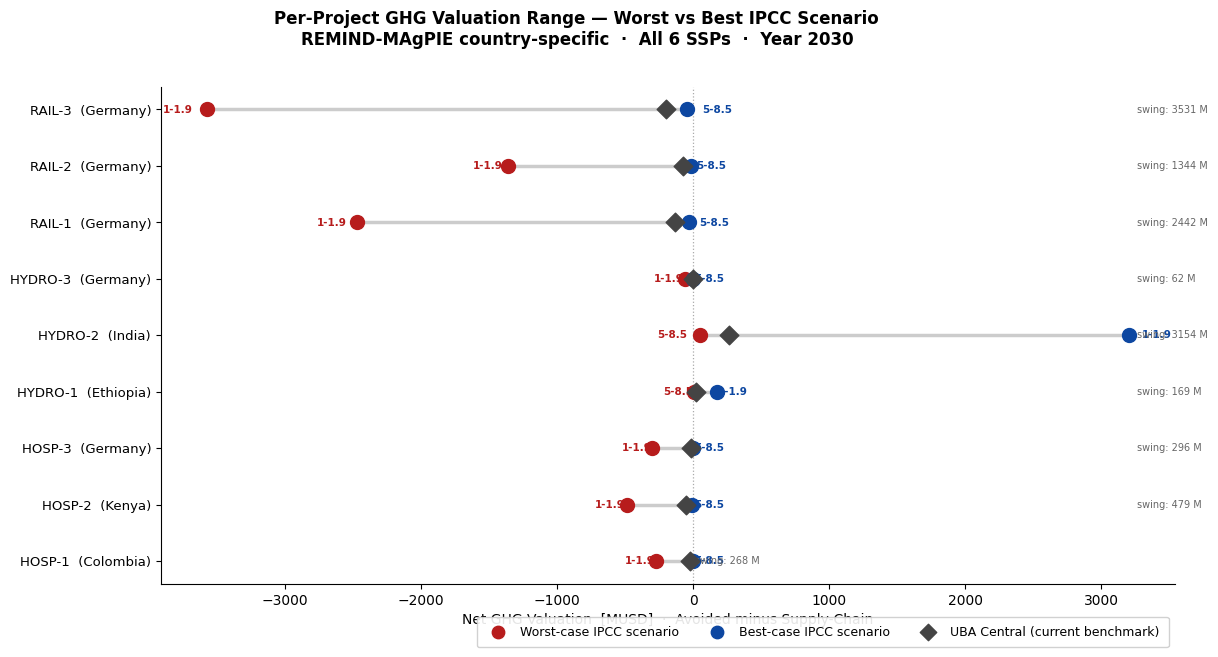

In [5]:
def fig1_per_project(wdf):
    n   = len(wdf)
    y   = np.arange(n)
    fig, ax = plt.subplots(figsize=(13, 7))
    fig.subplots_adjust(top=0.86, bottom=0.15, left=0.18, right=0.96)

    for i, row in wdf.iterrows():
        yi = list(wdf.index).index(i)
        # Range line
        ax.plot([row['worst'], row['best']], [yi, yi],
                color='#ccc', lw=2.5, solid_capstyle='round', zorder=1)
        # Worst dot
        ax.scatter(row['worst'], yi,
                   color='#b71c1c', s=100, zorder=3, clip_on=False)
        # Best dot
        ax.scatter(row['best'], yi,
                   color='#0d47a1', s=100, zorder=3, clip_on=False)
        # UBA diamond
        ax.scatter(row['uba'], yi,
                   color='#444', s=90, marker='D', zorder=4, clip_on=False)

        # Scenario labels
        w_lbl = row['worst_ssp'].replace('SSP', '')
        b_lbl = row['best_ssp'].replace('SSP', '')
        pad   = max(abs(row['swing']) * 0.03, 4)
        ax.text(row['worst'] - pad, yi, w_lbl,
                ha='right', va='center', fontsize=7.5,
                color='#b71c1c', fontweight='bold')
        ax.text(row['best'] + pad, yi, b_lbl,
                ha='left',  va='center', fontsize=7.5,
                color='#0d47a1', fontweight='bold')

        # Swing annotation on right margin
        ax.text(ax.get_xlim()[1] if i == 0 else wdf['best'].max() * 1.02,
                yi, f"swing: {row['swing']:.0f} M",
                ha='left', va='center', fontsize=7, color='#666')

    ax.set_yticks(range(n))
    ax.set_yticklabels(
        [f"{r['project']}  ({r['country']})" for _, r in wdf.iterrows()],
        fontsize=9.5
    )
    ax.axvline(0, color='#aaa', lw=0.9, ls=':', zorder=0)
    ax.set_xlabel('Net GHG Valuation  [MUSD]  ·  Avoided minus Supply-Chain', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)

    # Legend
    legend_elements = [
        plt.scatter([], [], color='#b71c1c', s=80,  label='Worst-case IPCC scenario'),
        plt.scatter([], [], color='#0d47a1', s=80,  label='Best-case IPCC scenario'),
        plt.scatter([], [], color='#444',    s=70, marker='D', label='UBA Central (current benchmark)'),
    ]
    ax.legend(handles=legend_elements, fontsize=9, framealpha=0.9,
              loc='lower right', bbox_to_anchor=(1.0, -0.14),
              ncol=3, borderpad=0.7)

    fig.suptitle(
        'Per-Project GHG Valuation Range — Worst vs Best IPCC Scenario\n'
        'REMIND-MAgPIE country-specific  ·  All 6 SSPs  ·  Year 2030',
        fontsize=12, fontweight='bold', y=0.97
    )
    fig.savefig(FIG_DIR / 'comm_fig1_per_project.png', dpi=150, bbox_inches='tight')
    plt.show()


fig1_per_project(wdf)

---
## Figure 2 — Sector Worst / Best
**Message:** Which sector carries the most transition risk?  
**Design:** Three grouped bars per sector (worst · UBA · best) with percentage delta labels.

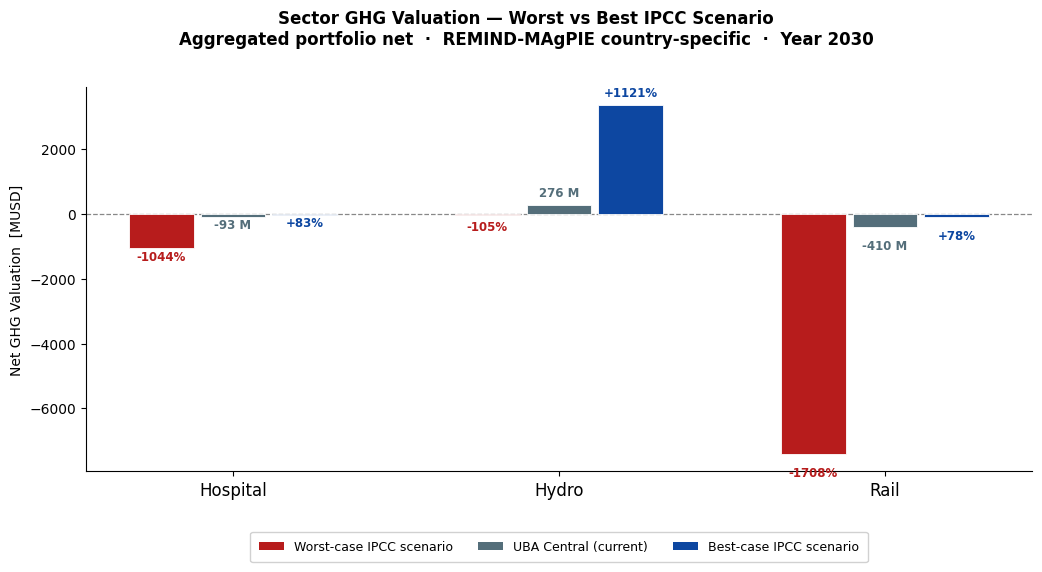

In [6]:
def fig2_sector(wdf):
    sector_order  = ['Hospital', 'Hydro', 'Rail']
    sector_colors = {'Hospital': '#78909c', 'Hydro': '#1976d2', 'Rail': '#e67e22'}

    # Aggregate to sector level
    sec_agg = (
        wdf.groupby('sector')[['uba', 'worst', 'best']]
           .sum()
           .reindex(sector_order)
    )

    x   = np.arange(len(sector_order))
    bw  = 0.22
    fig, ax = plt.subplots(figsize=(11, 6))
    fig.subplots_adjust(top=0.84, bottom=0.20, left=0.10, right=0.96)

    for xi, sec in enumerate(sector_order):
        uba_v   = sec_agg.loc[sec, 'uba']
        worst_v = sec_agg.loc[sec, 'worst']
        best_v  = sec_agg.loc[sec, 'best']
        col     = sector_colors[sec]

        # Three bars: worst · UBA · best
        ax.bar(xi - bw, worst_v, width=bw * 0.9, color='#b71c1c',
               edgecolor='white', lw=0.6, zorder=3)
        ax.bar(xi,      uba_v,   width=bw * 0.9, color='#546e7a',
               edgecolor='white', lw=0.6, zorder=3)
        ax.bar(xi + bw, best_v,  width=bw * 0.9, color='#0d47a1',
               edgecolor='white', lw=0.6, zorder=3)

        # Delta labels above / below each bar
        def pct(v, base):
            return f"{'+' if v >= base else ''}{(v - base) / abs(base) * 100:.0f}%" if base != 0 else ""

        off = max(abs(worst_v), abs(best_v), abs(uba_v)) * 0.05 + 3
        for val, xoff, clr, lbl in [
            (worst_v, -bw, '#b71c1c', pct(worst_v, uba_v)),
            (uba_v,    0,  '#546e7a', f"{uba_v:.0f} M"),
            (best_v,  +bw, '#0d47a1', pct(best_v,  uba_v)),
        ]:
            va  = 'bottom' if val >= 0 else 'top'
            adj = off if val >= 0 else -off
            ax.text(xi + xoff, val + adj, lbl,
                    ha='center', va=va, fontsize=8.5,
                    fontweight='bold', color=clr)

    ax.axhline(0, color='#888', lw=0.9, ls='--')
    ax.set_xticks(x)
    ax.set_xticklabels(sector_order, fontsize=12)
    ax.set_ylabel('Net GHG Valuation  [MUSD]', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)

    # Legend below x-axis
    legend_elements = [
        mpatches.Patch(fc='#b71c1c', label='Worst-case IPCC scenario'),
        mpatches.Patch(fc='#546e7a', label='UBA Central (current)'),
        mpatches.Patch(fc='#0d47a1', label='Best-case IPCC scenario'),
    ]
    ax.legend(handles=legend_elements, fontsize=9, framealpha=0.9,
              loc='upper center', bbox_to_anchor=(0.5, -0.14),
              ncol=3, borderpad=0.7)

    fig.suptitle(
        'Sector GHG Valuation — Worst vs Best IPCC Scenario\n'
        'Aggregated portfolio net  ·  REMIND-MAgPIE country-specific  ·  Year 2030',
        fontsize=12, fontweight='bold', y=0.97
    )
    fig.savefig(FIG_DIR / 'comm_fig2_sector.png', dpi=150, bbox_inches='tight')
    plt.show()


fig2_sector(wdf)

---
## Figure 3 — Country Worst / Best
**Message:** Country exposure varies dramatically — where you invest matters as much as what you invest in.  
**Design:** Horizontal range bars per country (worst-to-best shaded band) with UBA as a marker line.

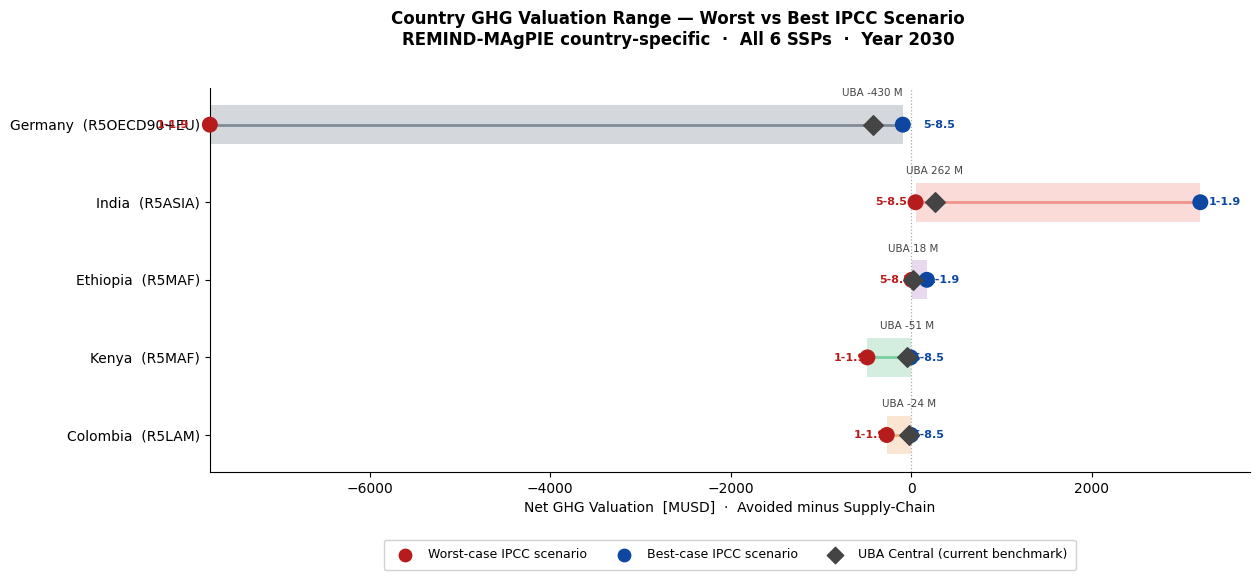

In [7]:
def fig3_geography(wdf):
    country_order = ['Colombia', 'Kenya', 'Ethiopia', 'India', 'Germany']
    CTRY_COLOR    = {
        'Colombia': '#e67e22',
        'Kenya':    '#27ae60',
        'Ethiopia': '#8e44ad',
        'India':    '#e74c3c',
        'Germany':  '#2c3e50',
    }
    CTRY_REGION = {
        'Colombia': 'R5LAM',
        'Kenya':    'R5MAF',
        'Ethiopia': 'R5MAF',
        'India':    'R5ASIA',
        'Germany':  'R5OECD90+EU',
    }

    # Aggregate to country level
    ctry_agg = (
        wdf.groupby('country')[['uba', 'worst', 'best']]
           .sum()
           .reindex(country_order)
    )
    ctry_worst_ssp = (
        wdf.groupby('country')['worst_ssp']
           .agg(lambda x: x.mode()[0])
    )
    ctry_best_ssp = (
        wdf.groupby('country')['best_ssp']
           .agg(lambda x: x.mode()[0])
    )

    n   = len(country_order)
    y   = np.arange(n)
    fig, ax = plt.subplots(figsize=(13, 6))
    fig.subplots_adjust(top=0.84, bottom=0.20, left=0.14, right=0.94)

    for yi, country in enumerate(country_order):
        worst_v = ctry_agg.loc[country, 'worst']
        best_v  = ctry_agg.loc[country, 'best']
        uba_v   = ctry_agg.loc[country, 'uba']
        col     = CTRY_COLOR[country]

        # Shaded range band
        ax.barh(yi, best_v - worst_v, left=worst_v, height=0.5,
                color=col, alpha=0.20, zorder=1)
        # Range end markers
        ax.scatter([worst_v, best_v], [yi, yi],
                   color=['#b71c1c', '#0d47a1'], s=110, zorder=4, clip_on=False)
        # UBA vertical marker
        ax.scatter(uba_v, yi, color='#444', s=100,
                   marker='D', zorder=5, clip_on=False)
        # Connecting line
        ax.plot([worst_v, best_v], [yi, yi],
                color=col, lw=2, alpha=0.5, zorder=2)

        # Labels: scenario names
        pad = max(abs(best_v - worst_v) * 0.03, 5)
        w_lbl = ctry_worst_ssp.get(country, '')
        b_lbl = ctry_best_ssp.get(country, '')
        ax.text(worst_v - pad, yi,
                w_lbl.replace('SSP', ''),
                ha='right', va='center', fontsize=8,
                color='#b71c1c', fontweight='bold')
        ax.text(best_v + pad, yi,
                b_lbl.replace('SSP', ''),
                ha='left', va='center', fontsize=8,
                color='#0d47a1', fontweight='bold')
        # UBA value
        ax.text(uba_v, yi + 0.34, f"UBA {uba_v:.0f} M",
                ha='center', va='bottom', fontsize=7.5,
                color='#444')

    ax.set_yticks(y)
    ax.set_yticklabels(
        [f"{c}  ({CTRY_REGION[c]})" for c in country_order],
        fontsize=10
    )
    ax.axvline(0, color='#aaa', lw=0.9, ls=':', zorder=0)
    ax.set_xlabel('Net GHG Valuation  [MUSD]  ·  Avoided minus Supply-Chain', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)

    # Legend
    legend_elements = [
        plt.scatter([], [], color='#b71c1c', s=80,  label='Worst-case IPCC scenario'),
        plt.scatter([], [], color='#0d47a1', s=80,  label='Best-case IPCC scenario'),
        plt.scatter([], [], color='#444',    s=70, marker='D', label='UBA Central (current benchmark)'),
    ]
    ax.legend(handles=legend_elements, fontsize=9, framealpha=0.9,
              loc='upper center', bbox_to_anchor=(0.5, -0.16),
              ncol=3, borderpad=0.7)

    fig.suptitle(
        'Country GHG Valuation Range — Worst vs Best IPCC Scenario\n'
        'REMIND-MAgPIE country-specific  ·  All 6 SSPs  ·  Year 2030',
        fontsize=12, fontweight='bold', y=0.97
    )
    fig.savefig(FIG_DIR / 'comm_fig3_geography.png', dpi=150, bbox_inches='tight')
    plt.show()


fig3_geography(wdf)